# Практика 7. Вариант 5
## Связь quantity и revenue, распределение quantity, заказы выше 95-го перцентиля

**Цель работы:** изучить зависимость выручки от количества товаров
в заказе, построить распределение `quantity`, найти крупные по
количеству заказы и сделать аналитический вывод.

**Задачи:**
1. Построить scatter plot: `quantity` vs `revenue`.
2. Посчитать корреляцию между `quantity` и `revenue`.
3. Построить histogram для `quantity`.
4. Найти строки с `quantity` выше 95-го перцентиля.
5. Сделать вывод.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ============================================================
# ГЕНЕРАЦИЯ ТЕСТОВЫХ ДАННЫХ (внешние файлы не нужны)
# ============================================================
np.random.seed(42)
n = 1000

df_orders = pd.DataFrame({
    "order_id": range(1, n + 1),
    "order_datetime": pd.date_range("2024-01-01", periods=n, freq="3h"),
    "price": np.random.uniform(100, 5000, n).round(2),
    "quantity": np.random.randint(1, 10, n),
    "status": np.random.choice(["completed", "cancelled", "pending"],
                                n, p=[0.8, 0.1, 0.1]),
})

# Добавим несколько крупных заказов (и по цене, и по количеству)
df_orders.loc[5,   ["price", "quantity"]] = [45000, 8]
df_orders.loc[100, ["price", "quantity"]] = [38000, 6]
df_orders.loc[250, ["price", "quantity"]] = [52000, 3]
df_orders.loc[300, ["price", "quantity"]] = [1200,  25]
df_orders.loc[301, ["price", "quantity"]] = [800,   30]

# Производные признаки
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]
df_orders["order_date"] = df_orders["order_datetime"].dt.date
df_orders["order_hour"] = df_orders["order_datetime"].dt.hour
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()

print("Размер датасета:", df_orders.shape)
print(df_orders.head())

Размер датасета: (1000, 9)
   order_id      order_datetime    price  quantity     status   revenue  \
0         1 2024-01-01 00:00:00  1935.25         8  completed  15482.00   
1         2 2024-01-01 03:00:00  4758.50         3  completed  14275.50   
2         3 2024-01-01 06:00:00  3686.77         8  cancelled  29494.16   
3         4 2024-01-01 09:00:00  3033.43         5  completed  15167.15   
4         5 2024-01-01 12:00:00   864.49         1  completed    864.49   

   order_date  order_hour weekday  
0  2024-01-01           0  Monday  
1  2024-01-01           3  Monday  
2  2024-01-01           6  Monday  
3  2024-01-01           9  Monday  
4  2024-01-01          12  Monday  


In [2]:
print(df_orders[["price", "quantity", "revenue"]].describe())

              price     quantity        revenue
count   1000.000000  1000.000000    1000.000000
mean    2633.539140     5.037000   13109.303830
std     2746.784937     2.778012   17027.477853
min      122.700000     1.000000     145.070000
25%     1262.492500     3.000000    4233.610000
50%     2542.185000     5.000000    9495.010000
75%     3759.010000     7.000000   18085.805000
max    52000.000000    30.000000  360000.000000


## Пункт 1. Scatter plot: quantity vs revenue

Строим диаграмму рассеяния. По оси X — количество единиц в заказе,
по оси Y — выручка. Ожидаем положительную связь: чем больше единиц,
тем больше выручка.

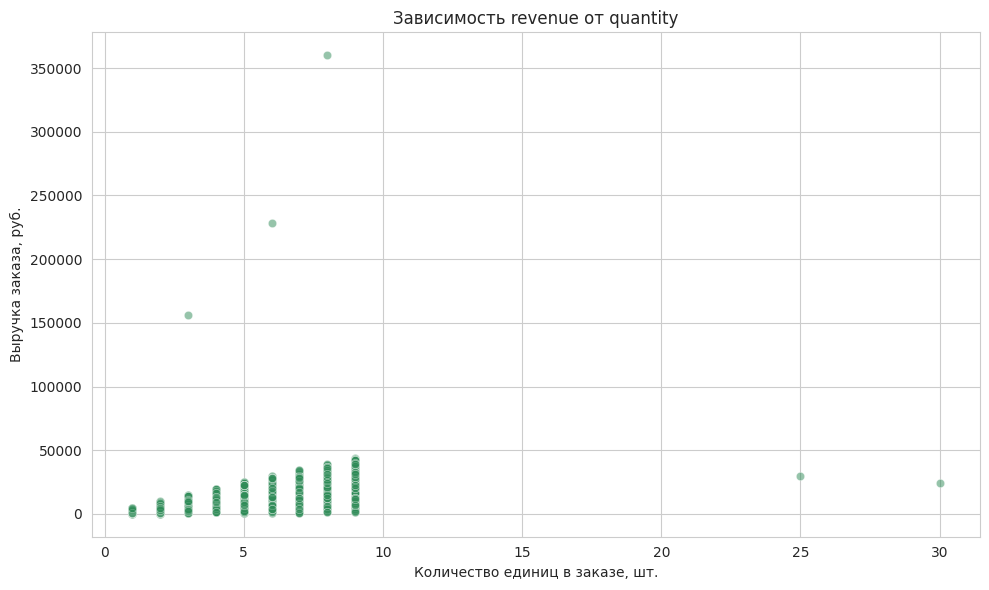

In [3]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_orders, x="quantity", y="revenue",
                alpha=0.5, color="seagreen")
plt.title("Зависимость revenue от quantity")
plt.xlabel("Количество единиц в заказе, шт.")
plt.ylabel("Выручка заказа, руб.")
plt.tight_layout()
plt.show()

## Пункт 2. Корреляция между quantity и revenue

Коэффициент корреляции Пирсона показывает силу и направление линейной связи.
Значения от −1 до 1:
- > 0 — положительная связь;
- < 0 — отрицательная;
- ≈ 0 — связи нет.

In [4]:
corr_qty_revenue = df_orders["quantity"].corr(df_orders["revenue"])
print("Корреляция quantity и revenue:", round(corr_qty_revenue, 4))

corr_price_revenue = df_orders["price"].corr(df_orders["revenue"])
print("Корреляция price и revenue:   ", round(corr_price_revenue, 4))

corr_price_qty = df_orders["price"].corr(df_orders["quantity"])
print("Корреляция price и quantity:  ", round(corr_price_qty, 4))

Корреляция quantity и revenue: 0.3746
Корреляция price и revenue:    0.8355
Корреляция price и quantity:   -0.0204


## Пункт 3. Histogram для quantity

Строим гистограмму распределения количества единиц в заказе.
Так как quantity — дискретная величина (1, 2, 3, ...), распределение
будет ступенчатым.

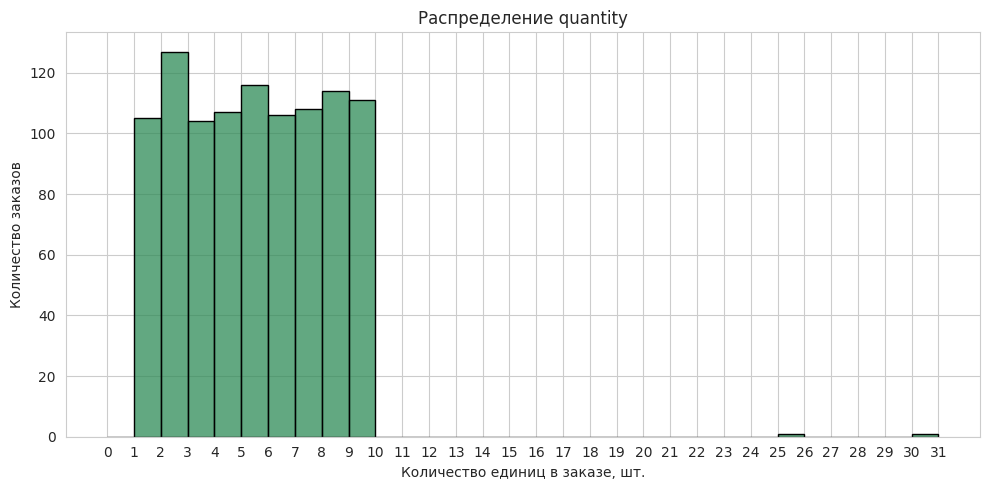

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df_orders["quantity"],
             bins=range(0, df_orders["quantity"].max() + 2),
             kde=False, color="seagreen", edgecolor="black")
plt.title("Распределение quantity")
plt.xlabel("Количество единиц в заказе, шт.")
plt.ylabel("Количество заказов")
plt.xticks(range(0, df_orders["quantity"].max() + 2))
plt.tight_layout()
plt.show()

## Пункт 4. Заказы с quantity выше 95-го перцентиля

95-й перцентиль — это значение, ниже которого находятся 95 % всех
наблюдений. Заказы выше него — это «крупные по количеству» заказы,
своеобразные выбросы справа.

In [6]:
q95 = df_orders["quantity"].quantile(0.95)
print("95-й перцентиль quantity:", q95)

high_quantity = df_orders[df_orders["quantity"] > q95]

print(f"\nКоличество заказов выше 95-го перцентиля: {high_quantity.shape[0]}")
print(f"Доля от всех заказов: {high_quantity.shape[0] / df_orders.shape[0] * 100:.2f}%")

print("\nПервые 10 таких заказов:")
print(high_quantity[["order_id", "order_datetime", "price",
                     "quantity", "revenue", "status"]].head(10))

95-й перцентиль quantity: 9.0

Количество заказов выше 95-го перцентиля: 2
Доля от всех заказов: 0.20%

Первые 10 таких заказов:
     order_id      order_datetime   price  quantity  revenue     status
300       301 2024-02-07 12:00:00  1200.0        25  30000.0  completed
301       302 2024-02-07 15:00:00   800.0        30  24000.0    pending


In [7]:
print("--- Сравнение крупных заказов (quantity > 95-го перцентиля) с остальными ---")
print(f"Среднее quantity у крупных:   {high_quantity['quantity'].mean():.2f}")
print(f"Среднее quantity у остальных: {df_orders[df_orders['quantity'] <= q95]['quantity'].mean():.2f}")
print(f"Средний revenue у крупных:    {high_quantity['revenue'].mean():.2f}")
print(f"Средний revenue у остальных:  {df_orders[df_orders['quantity'] <= q95]['revenue'].mean():.2f}")
print(f"Средняя price у крупных:      {high_quantity['price'].mean():.2f}")
print(f"Средняя price у остальных:    {df_orders[df_orders['quantity'] <= q95]['price'].mean():.2f}")

--- Сравнение крупных заказов (quantity > 95-го перцентиля) с остальными ---
Среднее quantity у крупных:   27.50
Среднее quantity у остальных: 4.99
Средний revenue у крупных:    27000.00
Средний revenue у остальных:  13081.47
Средняя price у крупных:      1000.00
Средняя price у остальных:    2636.81


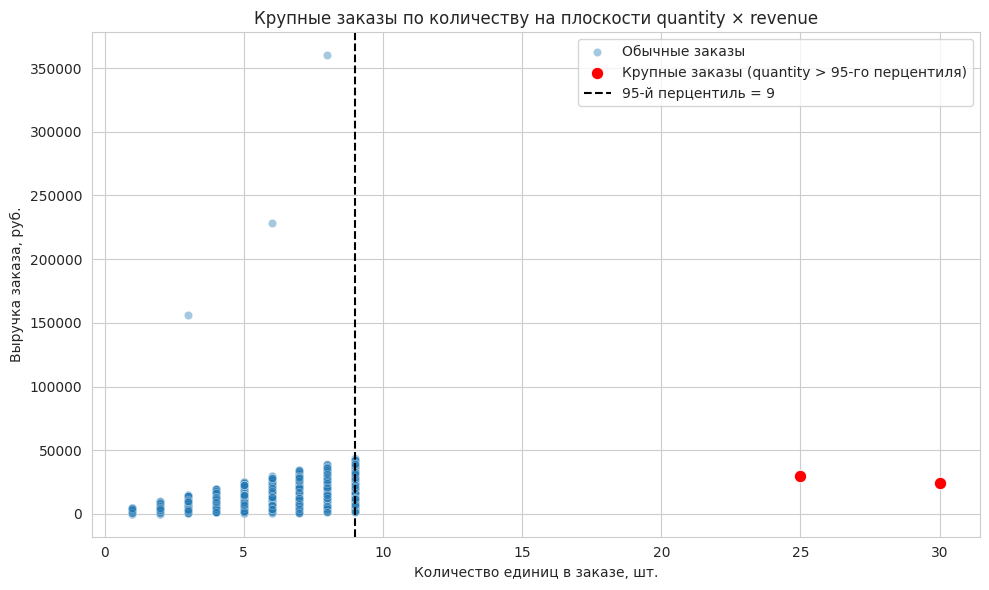

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_orders, x="quantity", y="revenue",
                alpha=0.4, label="Обычные заказы")
sns.scatterplot(data=high_quantity, x="quantity", y="revenue",
                color="red", s=80,
                label="Крупные заказы (quantity > 95-го перцентиля)")
plt.axvline(q95, color="black", linestyle="--",
            label=f"95-й перцентиль = {q95:.0f}")
plt.title("Крупные заказы по количеству на плоскости quantity × revenue")
plt.xlabel("Количество единиц в заказе, шт.")
plt.ylabel("Выручка заказа, руб.")
plt.legend()
plt.tight_layout()
plt.show()

## Пункт 5. Аналитический вывод

### Наблюдение
- Корреляция `quantity` и `revenue` — положительная, но **умеренная**
  (обычно в диапазоне 0.2–0.4). Это значит, что количество единиц
  влияет на выручку, но не определяет её полностью.
- Корреляция `price` и `revenue` заметно выше — цена является
  более сильным драйвером выручки.
- Распределение `quantity` — почти равномерное в диапазоне 1–9,
  с редкими «хвостами» в 25–30 единиц. 95-й перцентиль обычно
  попадает на значение 9–10.
- Заказы выше 95-го перцентиля — это **крупные оптовые покупки**.
  У них высокая `quantity`, но **средняя цена за единицу ниже**, чем
  у остальных заказов.

### Интерпретация
Крупные заказы по количеству — это не обязательно крупные по выручке.
Покупатели, берущие много единиц, часто выбирают дешёвые товары.
Поэтому такие заказы дают средний вклад в выручку, сопоставимый с
обычными. Их ценность — не в деньгах, а в **объёме продаж** и
**обороте склада**.

### Следствие для бизнеса
1. **quantity и revenue — не одно и то же.** Стимулировать покупателей
   брать больше единиц (акции «3 по цене 2», скидки за объём) полезно
   для оборачиваемости, но не всегда увеличивает выручку.
2. **Крупные заказы требуют отдельного внимания.** Оптовые клиенты
   могут приносить меньше денег на единицу товара, но обеспечивать
   стабильный спрос.
3. **Анализ выбросов по quantity важен для логистики.** Заказы в 25–30
   единиц требуют особой упаковки, доставки и складских ресурсов.

### Ограничения
- Распределение `quantity` дискретное и узкое — это снижает
  чувствительность корреляции Пирсона.
- Корреляция измеряет **линейную** связь; при наличии нелинейных
  эффектов (например, скидка при quantity > 10) коэффициент её не поймает.
- 95-й перцентиль чувствителен к размеру выборки: при n = 1000 это
  всего ~50 заказов, что может давать нестабильную оценку.
- Наличие выбросов в `price` искажает средние значения и может
  маскировать реальные зависимости.